# Calculate the horizontal propagation angle for GW packets over the Andes mountains in 2014

Author: Brian Green (briangre@stanford.edu)

In [1]:
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import numpy as np
import pandas as pd
from dataclasses import dataclass
import warnings
from scipy.ndimage import label
from scipy.ndimage import gaussian_filter
from scipy import interpolate
import scipy.signal
from mpl_toolkits.basemap import Basemap
warnings.simplefilter("ignore")

# For determining which times are day or night
import datetime
import pytz
import timezonefinder
import astral, astral.sun
from tqdm.notebook import tqdm

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    tqdm.pandas()
    
# Replace Basemap with Cartopy:
import cartopy.crs as ccrs
import matplotlib.ticker as mticker

### Constants

In [2]:
# Physical constants
g = 9.806 # (m/s**2); acceleration due to gravity
cp = 1005 # (J/kg/K); the specific heat at constant pressure
R = 287 # (J/kg/K); the gas constant for dry air
Omega = 7.27E-5 # (s-1); the rotation rate of the Earth

# Time series properties
dt = 2.0 # (minutes) the time step of the interpolated data

# Set the GW period range
GW_PERIOD_MIN = 10     # (minutes) the minimum period for GW packets is the maximum of this and the buoyancy period
GW_PERIOD_MAX = 1*24*60 # (minutes) the maximum period for GW packets is the minimum of this and the Coriolis period

# Parameters for identifying and quantifying maxima in the total momentum flux wavelet
STENCIL_DIM = 3 # (must be an odd number) the size of the stencil for averaging quantities near the momentum flux
                # maximum. The stencil has a size STENCIL_DIM x STENCIL_DIM wavelet coefficients, centered on the maximum
FLUX_THRESHOLD = 50 # (mPa) the threshold of the frequency-integrated total momentum flux to look identify times
                    # to look for maxima

# Wavelet parameters
omega0 = 8 # the normalized Morlet wavelet frequency
dj = 1/24 # Morlet wavelet transform parameter; see Section 3f of Torrence and Compo '98

### Load in the data

In [3]:
flights = pd.read_feather('5_flights_interptime_2daysegments_new_commontime.feather')
flights

# Select just the flights that start in 2014
flight_time_start = flights.groupby('flight_id').apply(lambda f: f.time.iloc[0])
flight_ids = flight_time_start[flight_time_start < pd.Timestamp('2015-01-01 00:00:00')]
flight_ids = flight_ids[flight_ids >= pd.Timestamp('2014-01-01 00:00:00')]
flights = flights[flights.flight_id.isin(flight_ids.index)]

# Select segments that fly inside a lat/lon box
# Andes:
lat_box_min = -55
lat_box_max = -30
lon_box_min = -80
lon_box_max = -60
flights[['in_box1','in_box2','in_box3','in_box4']] = 0
flights.loc[flights.latitude >= lat_box_min, 'in_box1'] = 1
flights.loc[flights.latitude <= lat_box_max, 'in_box2'] = 1
flights.loc[flights.longitude >= lon_box_min, 'in_box3'] = 1
flights.loc[flights.longitude <= lon_box_max, 'in_box4'] = 1
flights['in_box'] = flights.in_box1 + flights.in_box2 + flights.in_box3 + flights.in_box4
segments_to_select = flights[flights.in_box == 4].segment_id.unique()
flights = flights[flights.segment_id.isin(segments_to_select)]
flights = flights.drop(columns=['in_box1','in_box2','in_box3','in_box4','in_box'])

print('Number of flights:', flights.flight_id.nunique())
print('Number of segments:', flights.segment_id.nunique())
flights

Number of flights: 88
Number of segments: 145


,flight_id,time,latitude,longitude,altitude,pressure,wind_u,wind_v,T_cosmic,dTdz_cosmic,N_cosmic,altitude_spike,segment_id,segment_id_old
100259,I-152,2014-02-27 00:22:00,-45.019788,171.600930,20717.305639,51.142169,7.700098,-6.296178,-56.948675,0.001524,56.761456,0.0,103,230
100260,I-152,2014-02-27 00:24:00,-45.026600,171.612771,20722.023026,51.111022,7.821734,-6.697428,-56.884891,0.001532,55.000000,0.0,103,230
100261,I-152,2014-02-27 00:26:00,-45.034129,171.624677,20723.230667,51.128586,7.892786,-7.016287,-56.882967,0.001532,55.000000,0.0,103,230
100262,I-152,2014-02-27 00:28:00,-45.041954,171.636715,20739.869170,50.980000,8.047793,-7.375461,-56.941746,0.001561,53.000000,0.0,103,230
100263,I-152,2014-02-27 00:30:00,-45.049842,171.649040,20720.902664,51.109925,8.217200,-7.501751,-56.970601,0.001556,53.000000,0.0,103,230
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2505042,I-364,2014-11-06 18:22:00,-37.087434,-69.869284,19568.737114,60.221955,3.778921,-4.574958,-61.241210,0.001400,34.000000,0.0,5719,6014
2505043,I-364,2014-11-06 18:24:00,-37.092022,-69.863828,19574.523699,60.171672,4.686426,-3.615087,-61.233084,0.001400,34.378184,0.0,5719,6014
2505044,I-364,2014-11-06 18:26:00,-37.095055,-69.856907,19593.634262,60.011183,5.848624,-2.321166,-61.206291,0.001397,35.000000,0.0,5719,6014
2505045,I-364,2014-11-06 18:28:00,-37.096560,-69.847885,19583.103608,60.088727,6.807026,-1.781081,-61.221029,0.001400,35.000000,0.0,5719,6014


### Wavelet analysis function

In [5]:
## WAVELET ANALYSIS
# All equation and table numbers are from Torrence and Compo (1998)

# Create a dataclass for the variables returned from the analysis
@dataclass
class ReturnValue:
    N_pad: float;
    #X_recon: float;
    wave: float;
    #wave_power: float;
    #total_power: float;
    #global_power: float;
    global_power_rescaling: float;
    #total_global_power: float;
    C_delta: float;
    s: float;
    frequency: float;
    period: float;
    coi: float;
    #fftfreq: float;
    #fft: float;
    #fft_power: float;
    #fft_total_power: float;
    #fft_power_rescaling: float;
                    
# The input time series must have a mean of zero
def run_Morlet_CWT(X,dt,omega0,dj):
        
    N = np.size(X)
    std = np.std(X)
    var = std**2

    # Add zero padding and normalize to unit variance
    # The length of the new time series is 2*N for N even, 2*N + 1 for N odd
    N_pad = int(np.ceil(N/2))
    X_norm = np.zeros(N + 2*N_pad)
    X_norm[N_pad:N+N_pad] = X
    X_norm = X_norm/np.std(X_norm)
    N = N + 2*N_pad
    
    # Take the FFT of X_norm and make the frequencies (Eq. 5)
    X_norm_fft = np.fft.fft(X_norm)

    # Calculate the scales and Fourier equivalent frequencies and periods
    s0 = 2*dt*(omega0 + np.sqrt(2 + omega0**2))/(4*np.pi) # An inversion of Table 1 so the shortest period is 2*dt
    J = (1/dj)*np.log2(N*dt/s0) # (Eq. 10)
    J = int(np.ceil(J))
    s = s0*2**(dj*np.arange(J+1)) # (Eq. 9)
    s_tiled = np.tile(s,(N,1)).swapaxes(0,1)
    period = 4*np.pi*s/(omega0 + np.sqrt(2 + omega0**2)) # (Table 1) wavelet equivalent FFT period
    frequency = 1/period
    nscales = s.size
    
    # Loop through the scales to calculate the wavelet transform
    omega = 2*np.pi*np.fft.fftfreq(N)/dt # (Eq. 5) np.fft.fftfreq outputs (0,1,2,...)/N
    wave = np.nan*(1+1j)*np.ones(shape=(nscales,N))
    wave_delta = np.nan*np.ones(nscales)
    for i in np.arange(nscales):
        
        # Calculate the wavelet function (np.heaviside(0,0) = 0, so psi_hat(0) = 0 and the 
        # wavelet is admissible by construction (Section 3.3 of Farge 1992))
        psi_hat_0 = (np.pi**-0.25)*np.heaviside(omega,0)*np.exp(-0.5*(s[i]*omega - omega0)**2) # (Table 1)
        psi_hat = np.sqrt(2*np.pi*s[i]/dt)*psi_hat_0 # (Eq. 6) 
        
        # Calculate the wavelet transform
        wave[i,:] = np.fft.ifft(X_norm_fft*np.conj(psi_hat)) # (Eq. 4)
    
    # Estimate the reconstruction factor C_delta
    # Force the wavelet power spectrogram to have unit variance:
    C_delta = (dj*dt/N)*np.sum(np.abs(wave**2)/s_tiled) # (Eq. 14)
    
    ## Reconstruct the input time series
    #psi_0_0 = np.pi**-0.25 # (Table 2)
    #X_norm_recon = (dj*np.sqrt(dt)/(C_delta*psi_0_0))*np.sum(np.real(wave)/np.sqrt(s_tiled),axis=0) # (Eq. 11)
    
    # Calculate dimensional quantities
    N = N - 2*N_pad # N now matches the input time series length again
    ## The scaling is chosen so that the values are correct after the zero padding is removed
    #var_ratio = (N + 2*N_pad)/N # the reduction in variance due to the zero padding (= 2 for N even)
    #wave_power = (var/var_ratio)*np.abs(wave)**2
    #global_power = (1/N)*np.sum(wave_power, axis=1) # (Eq. 2)
    #total_power = (dj*dt/C_delta)*np.sum(wave_power/s_tiled, axis=0) # (Eq. 24)
    #total_global_power = (dj*dt/C_delta)*np.sum(global_power/s) # (Eq. 14)
    #global_total_power = (1/N)*np.sum(total_power)
    #X_recon = np.sqrt(var/var_ratio)*X_norm_recon # This (almost) equals the input time series + zero padding
    
    # Define a scaling so that the integral of the global power times the frequency
    # over the natural logarithm of the frequency equals the total variance. This helps
    # when plotting and comparing the global power spectrum to the FFT power spectrum.
    # Combining Eq. 9, Eq. 14, and Table 1:
    global_power_rescaling = (dt/C_delta)*4*np.pi*np.log2(np.exp(1))/(omega0+np.sqrt(2+omega0**2))
    
    # Calculate the COI (outputs the period versus time)
    coi = dt*np.arange(N)*(2**-0.5) # TC98 table 1
    coi = 4*np.pi*coi/(omega0 + np.sqrt(2 + omega0**2)) # (Table 1) wavelet equivalent FFT period
    coi = np.minimum(coi, np.flipud(coi))
    
    ## FFT analysis
    #ind_switchfreq_fft = 1 + int(np.floor(N/2))
    #fft = np.fft.fft(X/std)
    #fftfreq = np.fft.fftfreq(N,dt)
    #fft = fft[:ind_switchfreq_fft] # turn into a one-sided spectrum
    #fftfreq = np.abs(fftfreq[:ind_switchfreq_fft]) # turn into a one-sided spectrum
    #fft_power = (2*var/N)*np.abs(fft)**2 # dimensional power spectra 
    #fft_power[0] = fft_power[0]/2 # don't double-count the zero-frequency power
    #fft_total_power = (1/N)*np.sum(fft_power)
    #fft_power_rescaling = dt # a rescaling of fft_power so the integral over frequency = variance
        
    return ReturnValue(N_pad,
                       #X_recon,
                       wave,
                       #wave_power,
                       #total_power,
                       #global_power,
                       global_power_rescaling,
                       #total_global_power,
                       C_delta,
                       s,
                       frequency,
                       period,
                       coi)
                       #fftfreq,
                       #fft,
                       #fft_power,
                       #fft_total_power,
                       #fft_power_rescaling)

### Analyze the segment

In [6]:
def analyze_segment(segment,dt,omega0,dj,R,g,cp,Omega,
                    GW_PERIOD_MIN,GW_PERIOD_MAX,
                    STENCIL_DIM,FLUX_THRESHOLD,
                    lat_box_min,lat_box_max,lon_box_min,lon_box_max):

    # Convert time to a numpy array with units of minutes
    t = np.array((segment.time - segment.time.iloc[0])/pd.Timedelta('1 minutes'))
    N = np.size(t)
    # Make other variables arrays
    u = np.array(segment.wind_u)
    v = np.array(segment.wind_v)
    pt = 100*np.array(segment.pressure) # the Concordiasi data has pressure units of hPa; convert to Pa
    altitude = np.array(segment.altitude)
    balloon_lat = np.array(segment.latitude)
    balloon_lon = np.array(segment.longitude)
    T_env = np.array(segment.T_cosmic) + 273.15 # COSMIC temperatures are in degrees Celsius; convert to Kelvin
    dTdz_env = np.array(segment.dTdz_cosmic)
    altitude_spike = np.array(segment.altitude_spike)
    
    # When N_cosmic = 0, set T_env and dTdz_env to np.nan
    # Later, when flight-mean rho_bar, H, Nref, and Z_EDS are calculated, use np.nanmean
    N_cosmic = np.array(segment.N_cosmic)
    T_env[N_cosmic == 0] = np.nan
    dTdz_env[N_cosmic == 0] = np.nan
    T_env = T_env[altitude_spike == 0]
    dTdz_env = dTdz_env[altitude_spike == 0]
    
    # Calculate segment mean density. Because Loon temperature data is unreliable, use the
    # environmental temperature from the COSMIC profiles
    temp_pt = pt[altitude_spike == 0]
    rho_bar = np.nanmean(temp_pt/(R*T_env))
    
    # Calculate the segment mean temperature and lapse rate
    T_env = np.nanmean(T_env)
    dTdz_env = np.nanmean(dTdz_env)
    
    # Calculate the segment mean Coriolis parameter
    f = np.mean(2*Omega*np.sin(np.pi*balloon_lat/180))    
    
    # Calculate the segment mean environmental buoyancy frequency and Z_EDS
    Nref = np.sqrt((g/T_env)*((g/cp) + dTdz_env)) # VH14 Eq. 6
    Z_EDS = ((g/cp) + dTdz_env)/((g/R) + dTdz_env) # Vincent and Alexander 2020, Eq. 7
    
    # Create time series of anomalies by detrending
    u = scipy.signal.detrend(u)
    v = scipy.signal.detrend(v)
    delta_b = scipy.signal.detrend(altitude)
    
    # Calculate delta_theta and w, using Z_EDS
    delta_theta = delta_b/Z_EDS
    w = np.zeros(shape=(N)) # choose not to worry about the first and last value of w
    w[1:-1] = 0.5*(delta_theta[2:] - delta_theta[:-2])/(60*dt)
    
    # Run the wavelet analyses on the segment
    maxima_thetah_table = calc_maxima_thetah(t,w,u,v,delta_theta,balloon_lat,balloon_lon,
                                             omega0,dt,dj,
                                             Nref,rho_bar,Omega,Z_EDS,
                                             GW_PERIOD_MIN,GW_PERIOD_MAX,
                                             STENCIL_DIM,FLUX_THRESHOLD,
                                             lat_box_min,lat_box_max,lon_box_min,lon_box_max)
    
    return maxima_thetah_table

### Calculate energies, momentum fluxes

In [7]:
def calc_maxima_thetah(t,w,u,v,delta_theta,balloon_lat,balloon_lon,
                       omega0,dt,dj,
                       Nref,rho_bar,Omega,Z_EDS,
                       GW_PERIOD_MIN,GW_PERIOD_MAX,
                       STENCIL_DIM,FLUX_THRESHOLD,
                       lat_box_min,lat_box_max,lon_box_min,lon_box_max):

    N = np.size(t)

    # Time series' variance
    std_w = np.std(w)
    std_u = np.std(u)
    std_v = np.std(v)
    std_delta_theta = np.std(delta_theta)
    var_w = std_w**2
    var_u = std_u**2
    var_v = std_v**2
    var_delta_theta = std_delta_theta**2
    
    # Run the wavelet analysis
    w_output = run_Morlet_CWT(w,dt,omega0,dj)
    u_output = run_Morlet_CWT(u,dt,omega0,dj)
    v_output = run_Morlet_CWT(v,dt,omega0,dj)
    delta_theta_output = run_Morlet_CWT(delta_theta,dt,omega0,dj)
    # Pull out a couple common variables to make some calculations easier
    period = u_output.period; frequency = u_output.frequency; scale = u_output.s
    N_pad = u_output.N_pad; coi = u_output.coi
    C_delta = 0.5*(u_output.C_delta + v_output.C_delta)
    nscales = np.size(scale)
    var_ratio = (N + 2*N_pad)/N # the reduction in variance due to the zero padding (= 2 for N even)
    # Tile a couple variables
    scale_tiled_padded = np.tile(scale,(N + 2*N_pad,1)).swapaxes(0,1)
    period_tiled_padded = np.tile(period,(N + 2*N_pad,1)).swapaxes(0,1)
    
    
    
    ## CALCULATE THE ENERGY WAVELETS
    # Calculate the kinetic energies from the zero-padded wavelet output
    wave_Ekh = (0.5/var_ratio)*(var_u*u_output.global_power_rescaling*np.abs(u_output.wave)**2 + 
                                var_v*v_output.global_power_rescaling*np.abs(v_output.wave)**2)
    wave_Ekv = (0.5/var_ratio)*(var_w*w_output.global_power_rescaling*np.abs(w_output.wave)**2)
    # Calculate the potential energy from the zero-padded wavelet output
    wave_Ep = 0.5*(Nref**2)*(var_delta_theta/var_ratio)*delta_theta_output.global_power_rescaling* \
              np.abs(delta_theta_output.wave)**2 # Eq. 2, Podglajen et al 2016
    # Calculate total energy
    wave_Etotal = wave_Ekh + wave_Ekv + wave_Ep
    del wave_Ekh, wave_Ekv, wave_Ep
    
    
    
    ## CALCULATE THE U-W, V-W WAVELET CROSS-SPECTRA
    # Calculate the cross-spectra of u, v and the vertical velocity
    crossspec_u_w = w_output.wave*np.conj(u_output.wave) # this is the normalized spectrum
    crossspec_v_w = w_output.wave*np.conj(v_output.wave) # this is the normalized spectrum
    # Calculate C_delta so that the cross-spectral power is conserved, using the full
    # u-w and v-w cross-spectra
    uw_bar = np.nanmean(u*w)
    vw_bar = np.nanmean(v*w)
    temp = (std_u*std_w/var_ratio)*(dj*dt)* \
           np.sum(np.real(crossspec_u_w)/scale_tiled_padded, axis=0)
    C_delta_uw = (1/N)*np.sum(temp)/uw_bar
    temp = (std_v*std_w/var_ratio)*(dj*dt)* \
           np.sum(np.real(crossspec_v_w)/scale_tiled_padded, axis=0)
    C_delta_vw = (1/N)*np.sum(temp)/vw_bar
    cross_total_power_u_w = (std_u*std_w/var_ratio)*(dj*dt/C_delta_uw)* \
                            np.sum(np.real(crossspec_u_w)/scale_tiled_padded, axis=0)
    cross_total_power_v_w = (std_v*std_w/var_ratio)*(dj*dt/C_delta_vw)* \
                            np.sum(np.real(crossspec_v_w)/scale_tiled_padded, axis=0)
    
    
    
    ## CALCULATE THE TOTAL MOMENTUM FLUXES AND INTEGRATE THEM
    # Calculate the scaling factor for re-scaling the total energy
    balloon_lat_padded = np.nan*np.ones(N+2*N_pad)
    balloon_lat_padded[N_pad:N+N_pad] = balloon_lat
    balloon_lat_padded[:N_pad] = balloon_lat[0]
    balloon_lat_padded[N+N_pad:] = balloon_lat[-1]
    f_temp = np.tile(2*Omega*np.sin(np.pi*balloon_lat_padded/180),(nscales,1))
    frequency_rad = 2*np.pi*frequency/60
    frequency_rad = np.tile(frequency_rad,(N + 2*N_pad,1)).swapaxes(0,1)
    factor = (frequency_rad**2 - f_temp**2)/(Nref**2 - f_temp**2)
    factor = factor*(Nref**2 - frequency_rad**2)/(Nref**2 - f_temp**2)
    factor = rho_bar*np.sqrt(factor)
    del f_temp, frequency_rad
    # Do the scaling
    wave_Etotal_scaled = factor*wave_Etotal
    # Re-scale the u-w and v-w wavelet cross spectra and calculate the total momentum flux
    temp = rho_bar*(std_w/var_ratio)*(dt)*4*np.pi*np.log2(np.exp(1))/(omega0+np.sqrt(2+omega0**2))
    rescaled_ReUVW_total = temp*np.sqrt(np.real(std_u*crossspec_u_w/C_delta_uw)**2 + np.real(std_v*crossspec_v_w/C_delta_uw)**2)
    # Identify wavelet coefficients with periods higher than GW_PERIOD_MAX
    coeff_factor = 60*2*Omega*np.sin(np.pi*np.abs(balloon_lat_padded)/180) # Coriolis frequency in rad/min
    coeff_factor = 2*np.pi/coeff_factor # period in minutes
    coeff_factor = np.minimum(coeff_factor,GW_PERIOD_MAX)
    coeff_factor = np.tile(coeff_factor,(nscales,1))
    coeff_factor[coeff_factor < period_tiled_padded] = np.nan
    # Identify wavelet coefficients with periods lower than GW_PERIOD_MIN
    period_N = 2*np.pi/(60*Nref) # the buoyancy period
    min_period = np.maximum(GW_PERIOD_MIN,period_N)
    coeff_factor[period_tiled_padded < min_period] = np.nan
    coeff_factor = coeff_factor/coeff_factor
    # The total flux timeseries is equal to the integrals of the wavelet times frequency
    # over dlog(frequency), which is dj*np.log(2) (log base e).
    flux_total_Etotal = dj*np.log(2)*np.nansum(coeff_factor*wave_Etotal_scaled/period_tiled_padded, axis=0)
    flux_total_ReUVW = dj*np.log(2)*np.nansum(coeff_factor*rescaled_ReUVW_total/period_tiled_padded, axis=0)
    
    
    
    ## IDENTIFY MAXIMA IN THE TOTAL MOMENTUM FLUX WAVELET AND CALCULATE THEIR HORIZONTAL ANGLE
    # Find maxima by testing whether a value is greater than the eight others in its vicinity:
    # (x-axis: wavelet time; y_axis: wavelet period)
    #
    #   1    2    3
    #   4  value  5
    #   6    7    8
    #
    # Maxima near the edges are ignored, because they are outside the time or period ranges
    # of interest.
    field = wave_Etotal_scaled.copy()
    field_total_flux = flux_total_Etotal.copy()
    #field = rescaled_ReUVW_total.copy()
    #field_total_flux = flux_total_ReUVW.copy()
    maxima = np.zeros(shape=(nscales-2, N+2*N_pad-2))
    # Grid cell #1: up one in scale, back one time step
    temp = field[2:,:-2]
    maxima[field[1:-1,1:-1] > temp] = maxima[field[1:-1,1:-1] > temp] + 1
    # Grid cell #2: up one in scale, no time shift
    temp = field[2:,1:-1]
    maxima[field[1:-1,1:-1] > temp] = maxima[field[1:-1,1:-1] > temp] + 1
    # Grid cell #3: up one in scale, forward one time step
    temp = field[2:,2:]
    maxima[field[1:-1,1:-1] > temp] = maxima[field[1:-1,1:-1] > temp] + 1
    # Grid cell #4: no scale shift, back one time step
    temp = field[1:-1,:-2]
    maxima[field[1:-1,1:-1] > temp] = maxima[field[1:-1,1:-1] > temp] + 1
    # Grid cell #5: no scale shift, forward one time step
    temp = field[1:-1,2:]
    maxima[field[1:-1,1:-1] > temp] = maxima[field[1:-1,1:-1] > temp] + 1
    # Grid cell #6: down one in scale, back one time step
    temp = field[:-2,:-2]
    maxima[field[1:-1,1:-1] > temp] = maxima[field[1:-1,1:-1] > temp] + 1
    # Grid cell #7: down one in scale, no time shift
    temp = field[:-2,1:-1]
    maxima[field[1:-1,1:-1] > temp] = maxima[field[1:-1,1:-1] > temp] + 1
    # Grid cell #8: down one in scale, forward one time step
    temp = field[:-2,2:]
    maxima[field[1:-1,1:-1] > temp] = maxima[field[1:-1,1:-1] > temp] + 1
    del temp
    # There is a maximum when maxima = 8:
    maxima[maxima < 8] = 0
    maxima[maxima == 8] = 1
    # Change the shape of the maxima so that it has the same dimensions as wavelet
    # output (nscales,N+2*N_pad)
    temp = maxima.copy()
    maxima = np.zeros(shape=(nscales, N+2*N_pad))
    maxima[1:-1,1:-1] = temp
    del temp
    # Eliminate maxima in the zero padding regions
    maxima[:,:N_pad] = 0
    maxima[:,N+N_pad:] = 0
    # Eliminate maxima outside the GW frequency range
    maxima[np.isnan(coeff_factor) == True] = 0
    # Eliminate maxima inside the COI
    temp = np.zeros(N+2*N_pad)
    temp[N_pad:N+N_pad] = coi
    temp = np.tile(temp,(nscales,1))
    maxima[period_tiled_padded > temp] = 0
    del temp
    # Eliminate maxima when the frequency-integrated GW momentum flux is below
    # a threshold
    temp = np.tile(1000*field_total_flux,(nscales,1))
    maxima[temp < FLUX_THRESHOLD] = 0
    del temp
    # Eliminate maxima where the balloon isn't over the Andes
    balloon_lon_padded = np.nan*np.ones(N+2*N_pad)
    balloon_lon_padded[N_pad:N+N_pad] = balloon_lon
    balloon_lon_padded[:N_pad] = balloon_lon[0]
    balloon_lon_padded[N+N_pad:] = balloon_lon[-1]
    temp_lat = np.tile(balloon_lat_padded,(nscales,1))
    temp_lon = np.tile(balloon_lon_padded,(nscales,1))
    temp = np.zeros(shape=(nscales,N+2*N_pad))
    temp[temp_lat >= lat_box_min] = temp[temp_lat >= lat_box_min] + 1
    temp[temp_lat <= lat_box_max] = temp[temp_lat <= lat_box_max] + 1
    temp[temp_lon >= lon_box_min] = temp[temp_lon >= lon_box_min] + 1
    temp[temp_lon <= lon_box_max] = temp[temp_lon <= lon_box_max] + 1
    del temp_lat, temp_lon
    maxima[temp < 4] = 0
    del temp
    n_maxima = int(np.sum(maxima))
    # Compile the maxima into lists of periods and times
    temp_time = np.tile(segment.time.iloc[0],(N+2*N_pad))
    temp_time[N_pad:N+N_pad] = segment.time
    temp_time[N+N_pad:] = segment.time.iloc[-1]
    temp_time = np.tile(temp_time,(nscales,1))
    maxima_time = temp_time[maxima == 1]
    maxima_period = period_tiled_padded[maxima == 1]
    maxima_period_ind = np.tile(np.arange(nscales),(N+2*N_pad,1)).swapaxes(0,1)
    maxima_time_ind = np.tile(np.arange(N+2*N_pad), (nscales,1))
    maxima_period_ind = maxima_period_ind[maxima == 1]
    maxima_time_ind = maxima_time_ind[maxima == 1]
    del temp_time
    # Calculate the horizontal angle as the acrtangent of x- and y-fields averaged
    # over a stencil around the maxima
    x_field = np.real(std_u*crossspec_u_w/C_delta_uw)
    y_field = np.real(std_v*crossspec_v_w/C_delta_vw)
    maxima_theta_h = np.nan*np.ones(n_maxima)
    for i in np.arange(n_maxima):     
        # Retrive the x- and y-fields over the stencil
        period_ind = maxima_period_ind[i] - int((STENCIL_DIM-1)/2) + np.arange(STENCIL_DIM)
        time_ind = maxima_time_ind[i] - int((STENCIL_DIM-1)/2) + np.arange(STENCIL_DIM)
        x_field_temp = x_field[period_ind,time_ind]
        y_field_temp = y_field[period_ind,time_ind]
        field_temp = field[period_ind,time_ind]
        # Normalize to unit length and weight by the magnitude of the field
        temp = np.sqrt(x_field_temp**2 + y_field_temp**2)
        x_field_temp = x_field_temp*field_temp/temp
        y_field_temp = y_field_temp*field_temp/temp    
        # Average their values, weighting them by 1/scale (could weight by frequency)
        # and take their arctangent
        weighting = np.tile(1/scale[period_ind],(STENCIL_DIM,1)).swapaxes(0,1)
        temp = x_field_temp/x_field_temp # in case there's NaNs
        x_field_temp = np.nansum(temp*x_field_temp*weighting)/np.nansum(temp*weighting)
        temp = y_field_temp/y_field_temp # in case there's NaNs
        y_field_temp = np.nansum(temp*y_field_temp*weighting)/np.nansum(temp*weighting)
        maxima_theta_h[i] = 180*np.arctan2(y_field_temp,x_field_temp)/np.pi
    
    
    
    ## ORGANIZE THE OUTPUT
    maxima_thetah_table = pd.DataFrame(columns=['time','period','theta_h'])
    maxima_thetah_table.time = maxima_time
    maxima_thetah_table.period = maxima_period
    maxima_thetah_table.theta_h = maxima_theta_h
    maxima_thetah_table = maxima_thetah_table.sort_values(by=['time']).reset_index(drop=True)
    
    return maxima_thetah_table

In [15]:
segment_ids = flights.segment_id.unique()
n_segments = flights.segment_id.nunique()

# Make the dataframe that will hold the fluxes
segments_analyzed = pd.DataFrame()

for i in np.arange(n_segments):
    segment = flights[flights.segment_id == segment_ids[i]]
    print('Analyzing segment', i+1, 'out of', n_segments, 'segments')
    print('Segment length:', segment.time.max() - segment.time.min())
    print('Current time:', datetime.datetime.now())
    temp = analyze_segment(segment,dt,omega0,dj,R,g,cp,Omega,
                           GW_PERIOD_MIN,GW_PERIOD_MAX,
                           STENCIL_DIM,FLUX_THRESHOLD,
                           lat_box_min,lat_box_max,lon_box_min,lon_box_max)
    temp['segment_id'] = segment.segment_id.iloc[0]
    temp['flight_id'] = segment.flight_id.iloc[0]
    segments_analyzed = segments_analyzed.append(temp, ignore_index=True)
    print('')

segments_analyzed.to_feather('Loon_Andes_thetaH_omega0_8_50mPaThresh_fluxEtot.feather') 

Analyzing segment 1 out of 145 segments
Segment length: 94 days 04:36:00
Current time: 2025-08-14 14:22:09.706118

Analyzing segment 2 out of 145 segments
Segment length: 41 days 14:34:00
Current time: 2025-08-14 14:22:55.133374

Analyzing segment 3 out of 145 segments
Segment length: 41 days 22:24:00
Current time: 2025-08-14 14:23:07.624088

Analyzing segment 4 out of 145 segments
Segment length: 41 days 22:56:00
Current time: 2025-08-14 14:23:20.164257

Analyzing segment 5 out of 145 segments
Segment length: 41 days 22:02:00
Current time: 2025-08-14 14:23:32.738777

Analyzing segment 6 out of 145 segments
Segment length: 33 days 12:34:00
Current time: 2025-08-14 14:23:45.338979

Analyzing segment 7 out of 145 segments
Segment length: 13 days 06:48:00
Current time: 2025-08-14 14:23:51.952629

Analyzing segment 8 out of 145 segments
Segment length: 19 days 02:26:00
Current time: 2025-08-14 14:23:54.407178

Analyzing segment 9 out of 145 segments
Segment length: 19 days 01:24:00
Current


Analyzing segment 73 out of 145 segments
Segment length: 2 days 01:54:00
Current time: 2025-08-14 14:25:34.366288

Analyzing segment 74 out of 145 segments
Segment length: 6 days 20:48:00
Current time: 2025-08-14 14:25:34.597179

Analyzing segment 75 out of 145 segments
Segment length: 4 days 05:44:00
Current time: 2025-08-14 14:25:35.721740

Analyzing segment 76 out of 145 segments
Segment length: 11 days 19:06:00
Current time: 2025-08-14 14:25:36.448463

Analyzing segment 77 out of 145 segments
Segment length: 3 days 08:04:00
Current time: 2025-08-14 14:25:38.436400

Analyzing segment 78 out of 145 segments
Segment length: 5 days 13:00:00
Current time: 2025-08-14 14:25:38.872835

Analyzing segment 79 out of 145 segments
Segment length: 2 days 10:20:00
Current time: 2025-08-14 14:25:39.917884

Analyzing segment 80 out of 145 segments
Segment length: 4 days 21:54:00
Current time: 2025-08-14 14:25:40.236158

Analyzing segment 81 out of 145 segments
Segment length: 2 days 00:24:00
Curre


Analyzing segment 144 out of 145 segments
Segment length: 2 days 00:20:00
Current time: 2025-08-14 14:28:02.663588

Analyzing segment 145 out of 145 segments
Segment length: 7 days 03:52:00
Current time: 2025-08-14 14:28:02.952109



In [4]:
# Load in data
maxima_thetah_table = pd.read_feather('Loon_Andes_thetaH_omega0_8_50mPaThresh_fluxEtot.feather')
maxima_thetah_table

,time,period,theta_h,segment_id,flight_id
0,2014-05-30 01:48:00,12.337687,-119.512136,103,I-152
1,2014-05-30 02:02:00,32.000000,-60.482654,103,I-152
2,2014-05-30 02:20:00,19.027314,4.724570,103,I-152
3,2014-05-30 03:46:00,10.678719,143.844214,103,I-152
4,2014-05-30 04:24:00,26.142647,82.380513,103,I-152
...,...,...,...,...,...
1857,2014-11-06 14:24:00,107.634741,-146.152359,5719,I-364
1858,2014-11-06 14:46:00,11.645225,93.632359,5719,I-364
1859,2014-11-06 15:26:00,15.101989,70.327504,5719,I-364
1860,2014-11-06 16:12:00,31.089022,26.261808,5719,I-364


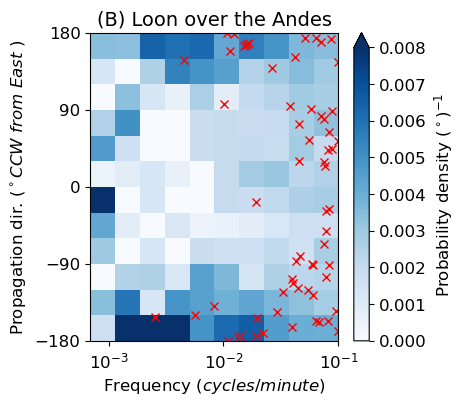

In [5]:
# Fig. 3B

# Select just the maxima from flight I-160, segment 112
segment_ids = np.array(maxima_thetah_table.segment_id)
segment_period = np.array(maxima_thetah_table.period)
segment_theta_h = np.array(maxima_thetah_table.theta_h)
segment_period = segment_period[segment_ids == 112]
segment_theta_h = segment_theta_h[segment_ids == 112]

# Plot everything together
n_theta_h_bins = 12
n_logfreq_bins = 10
temp_f = 2*Omega*np.sin(np.pi*np.abs(lat_box_max)/180)
logfreq_bins_max = np.log10(1/10)
logfreq_bins_min = np.log10(60*temp_f/(2*np.pi))
theta_h_edges = -180 + (360/n_theta_h_bins)*np.arange(n_theta_h_bins+1)
logfreq_edges = logfreq_bins_min + (logfreq_bins_max-logfreq_bins_min)*np.arange(n_logfreq_bins+1)/n_logfreq_bins # freq. in cyc/hr
H, xedges, yedges = np.histogram2d(np.log10(1/maxima_thetah_table.period), maxima_thetah_table.theta_h, 
                                   bins=(logfreq_edges,theta_h_edges))
# Do the pdf at each frequency
temp = np.tile(np.nansum(H, axis=1),(n_theta_h_bins,1)).swapaxes(0,1)
H = H/(temp*(360/n_theta_h_bins))

fig, ax3 = plt.subplots(figsize=(4,4))
plt.imshow(np.flipud(np.transpose(H)), interpolation='nearest', cmap='Blues',
           extent=[logfreq_edges[0], logfreq_edges[-1], theta_h_edges[0], theta_h_edges[-1]],
           origin='upper',aspect='auto')
plt.plot(np.log10(1/segment_period),segment_theta_h,'rx')
plt.clim(0,0.008)
cbar = plt.colorbar(extend='max')
cbar.set_label('Probability density ($^\circ$)$^{-1}$', fontsize=12)
cbar.ax.tick_params(labelsize=12)
plt.yticks([-180,-90,0,90,180])
plt.xticks([-3,-2,-1])
ax3.set_xticklabels(['$10^{-3}$','$10^{-2}$','$10^{-1}$'])
ax3.tick_params(labelsize=12)
plt.title('(B) Loon over the Andes', fontsize=14)
plt.ylabel('Propagation dir. $($$^\circ$$CCW$ $from$ $East$ $)$', fontsize=12)
plt.xlabel('Frequency $(cycles/minute)$', fontsize=12);
#plt.savefig('../plots/temp3.pdf', format='pdf', bbox_inches='tight');